## ML Lab:8
### Name: Mudit Rahangdale
### Section: C-C3
### Roll number: 41

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

In [4]:
df=pd.read_csv("ai4i2020 - ai4i2020.csv")

In [5]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [7]:
df.duplicated().sum()

np.int64(0)

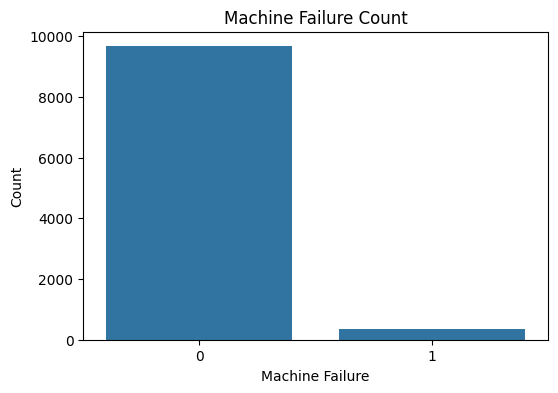

In [8]:
plt.figure(figsize=(6,4))
sns.countplot(x="Machine failure", data=df)
plt.title("Machine Failure Count")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.show()

In [9]:
numerical_features=[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

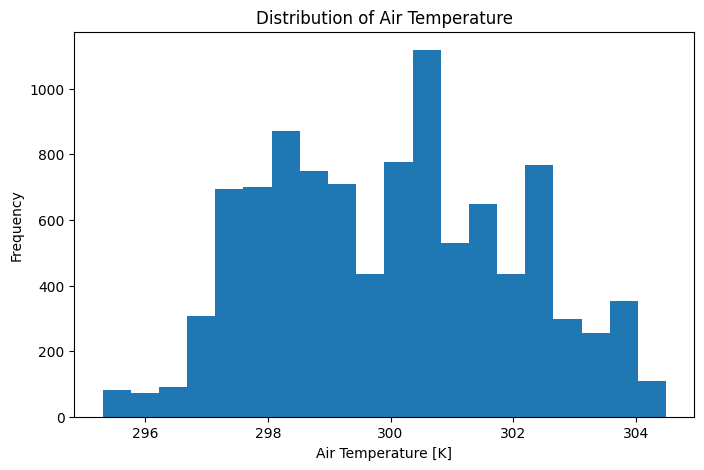

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df["Air temperature [K]"], bins=20)
plt.title("Distribution of Air Temperature")
plt.xlabel("Air Temperature [K]")
plt.ylabel("Frequency")
plt.show()

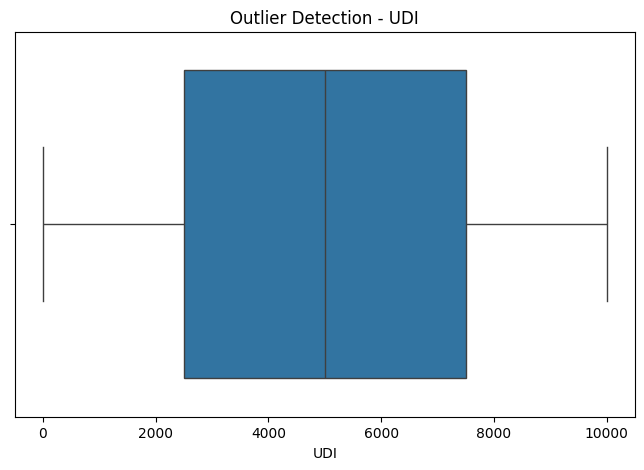

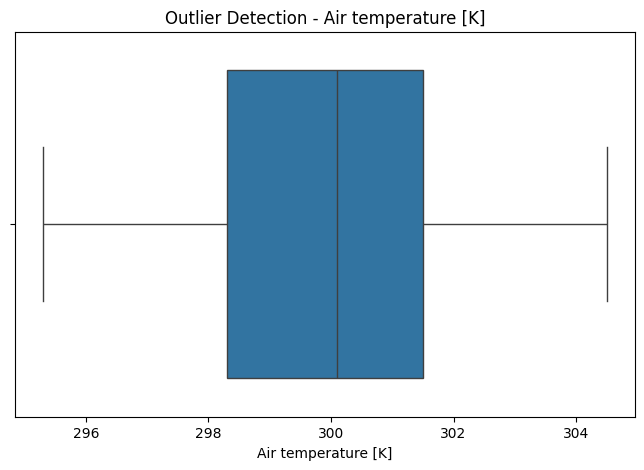

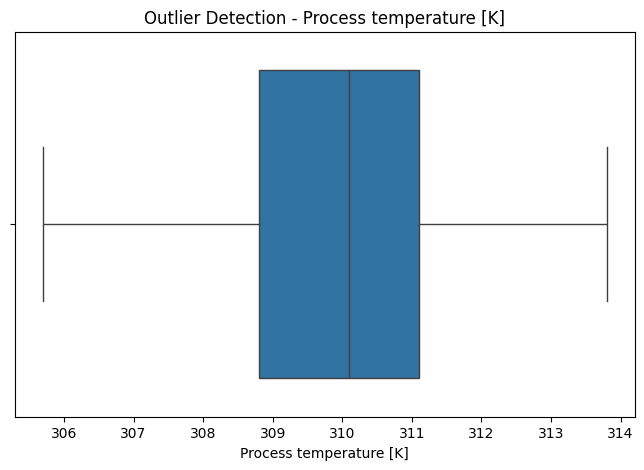

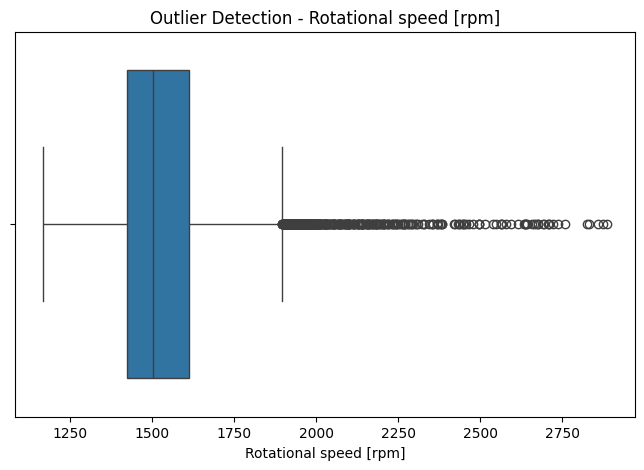

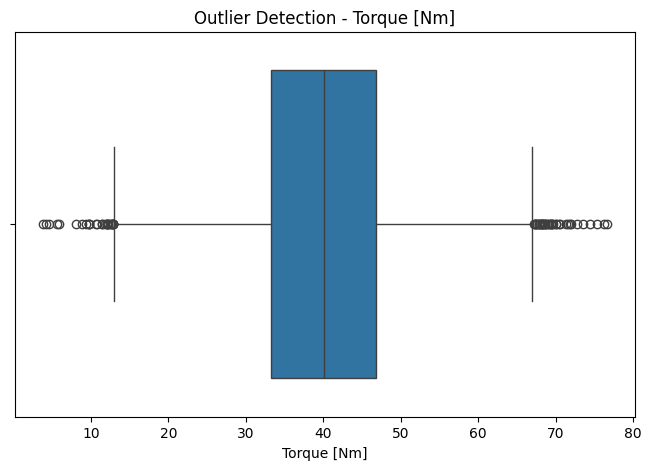

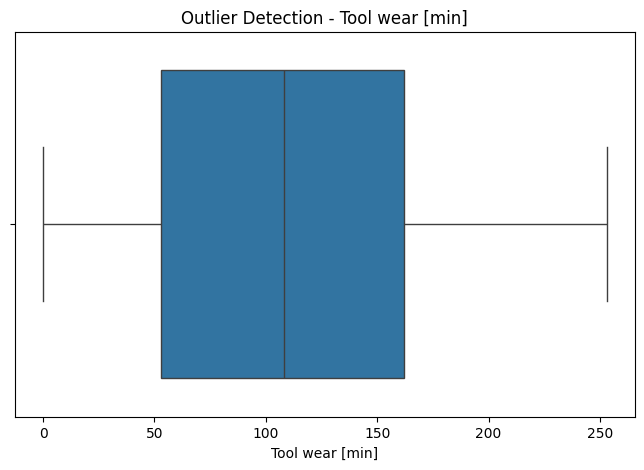

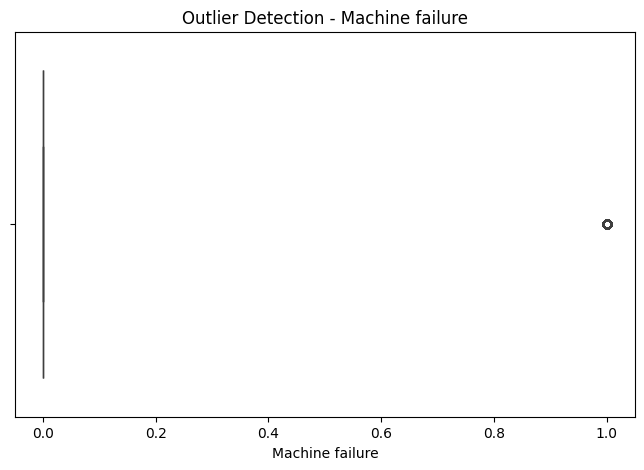

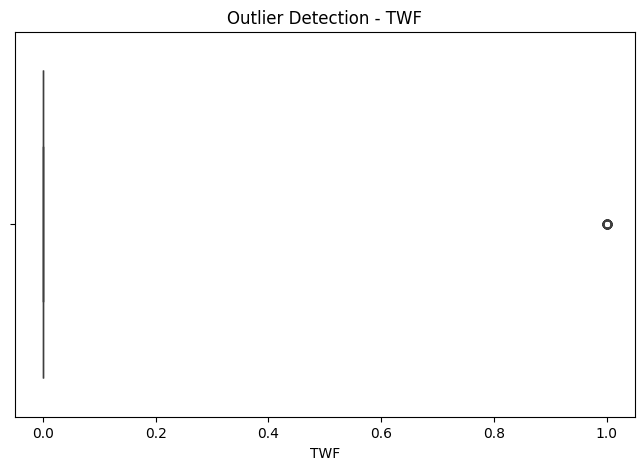

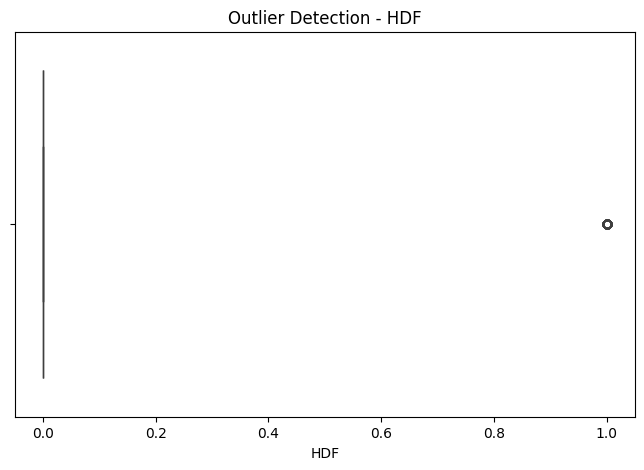

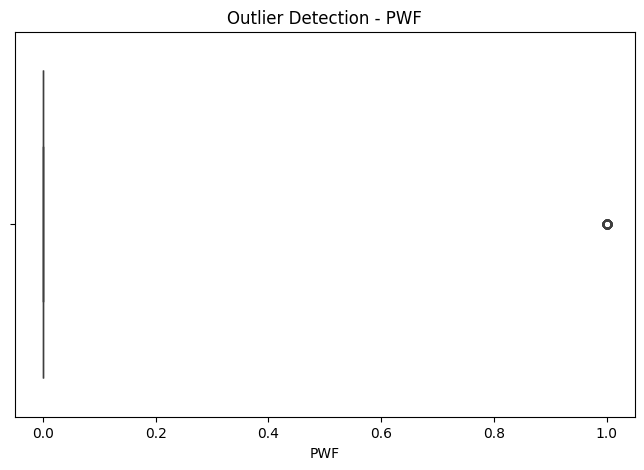

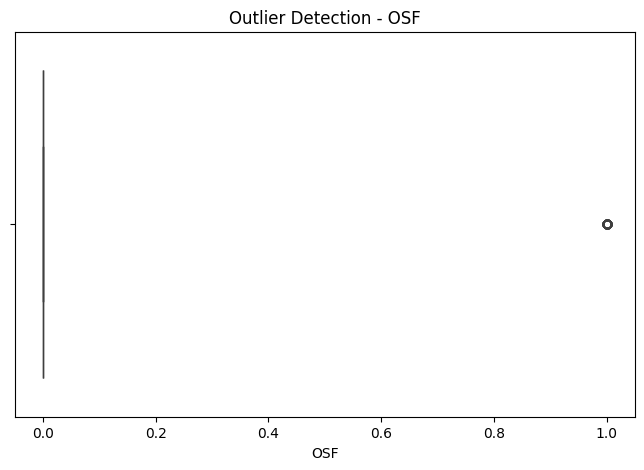

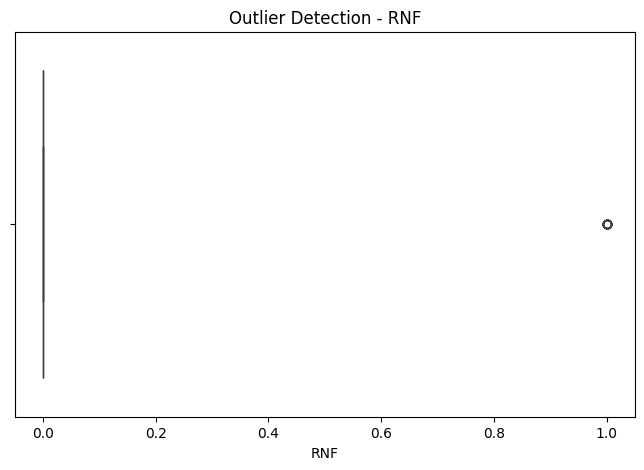

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns

for i in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=df[i])
    plt.title(f"Outlier Detection - {i}")
    plt.show()

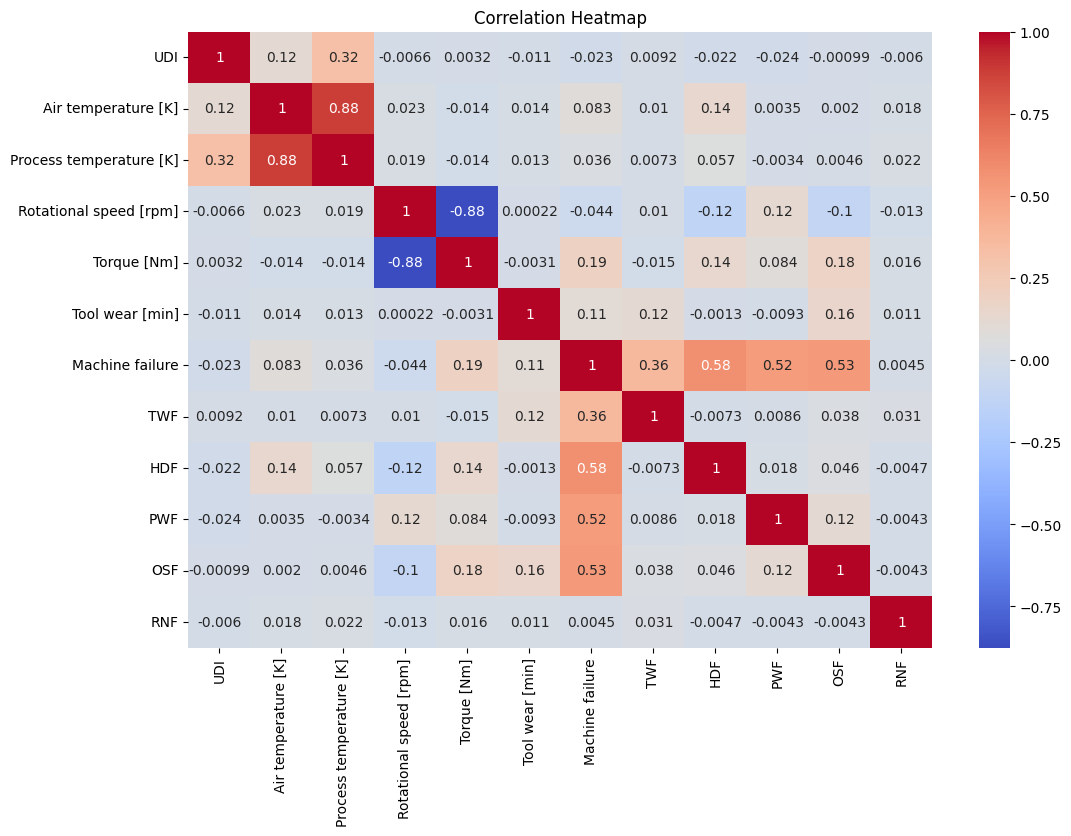

In [12]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

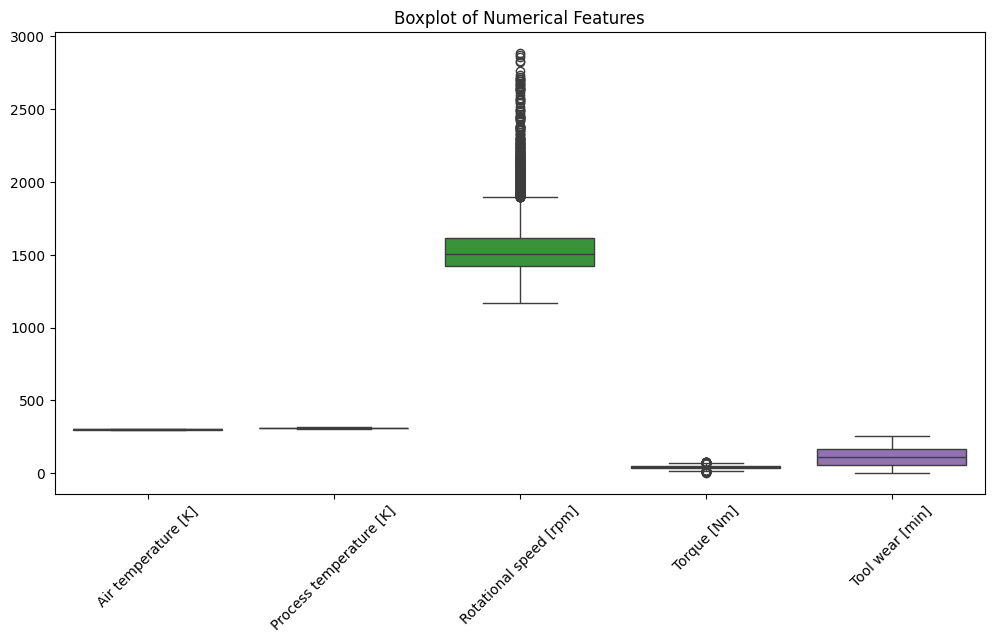

In [13]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numerical_features])
plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.show()

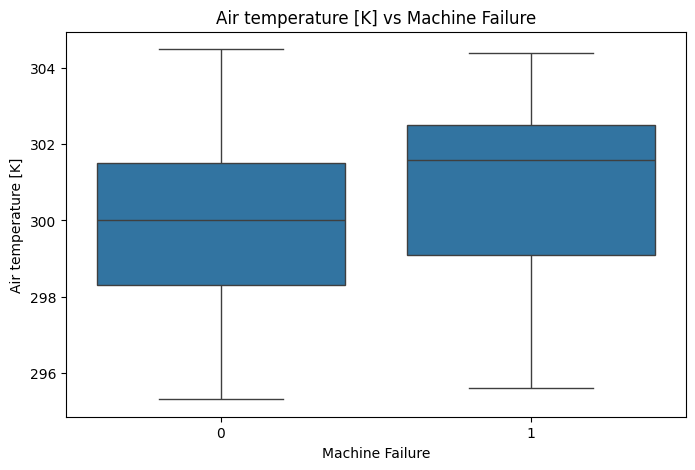

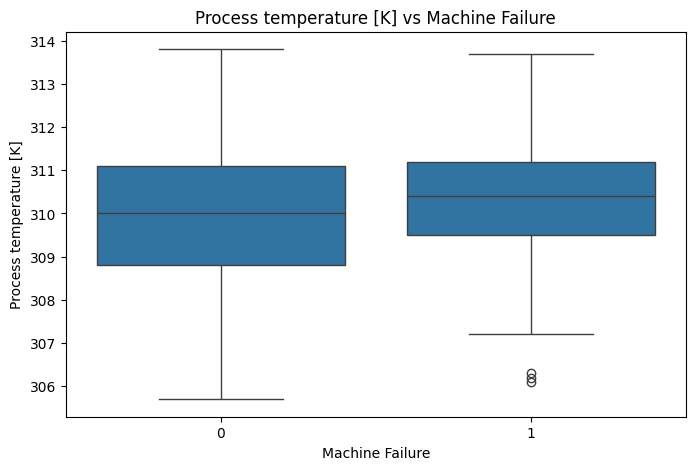

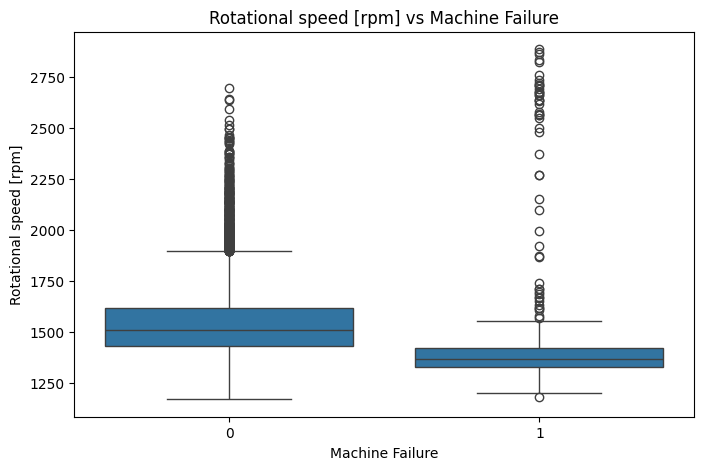

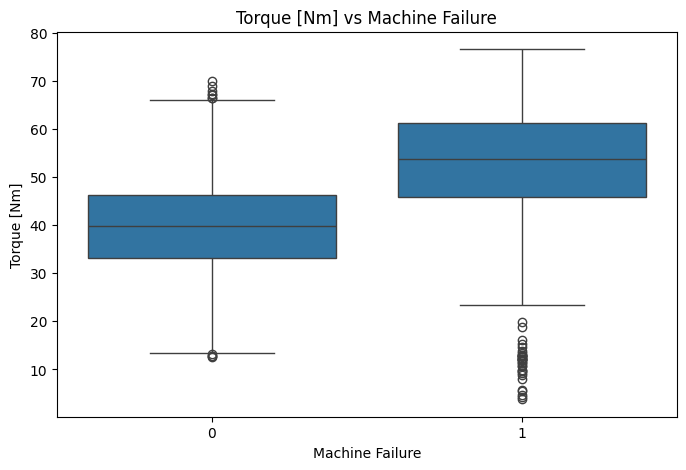

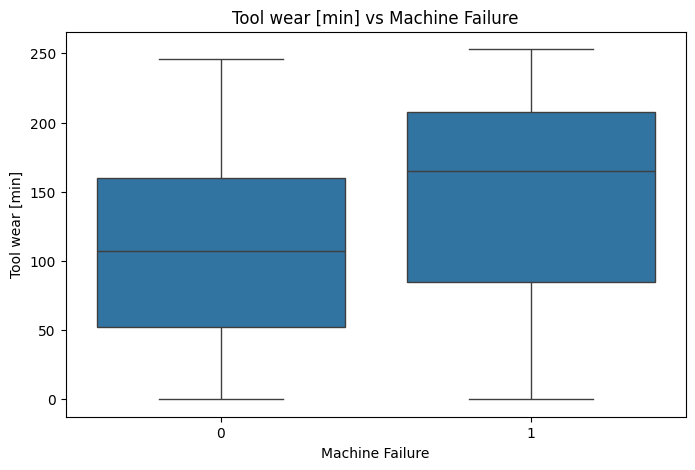

In [14]:
for i in numerical_features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x="Machine failure", y=i, data=df)
    plt.title(f"{i} vs Machine Failure")
    plt.xlabel("Machine Failure")
    plt.ylabel(i)
    plt.show()

In [15]:
X=df[
   [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
]

In [16]:
y = df["Machine failure"]

In [17]:
print("Input shape:",X.shape)
print("Output shape:",y.shape)

Input shape: (10000, 5)
Output shape: (10000,)


In [18]:
categorical_features=["Type"]

numerical_features=[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training sampples:", X_train.shape[0])
print("Testing sampples:", X_test.shape[0])

Training sampples: 8000
Testing sampples: 2000


In [20]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [21]:
linear_svm = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="linear"))
])

In [22]:
X = df.drop("Machine failure", axis=1)
y = df["Machine failure"]

In [23]:
print(X.columns)

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='object')


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
categorical_features = X.select_dtypes(include=["object"]).columns
numerical_features = X.select_dtypes(include=np.number).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [26]:
linear_svm = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="linear"))
])

In [27]:
linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['UDI', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'TWF',
       'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['Product ID', 'Type'], dtype='object'))])),
                ('classifier', SVC(kernel='linear'))])

In [28]:
y_pred = linear_svm.predict(X_test)

In [29]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.999
Precision: 1.0
Recall: 0.9705882352941176
F1 Score: 0.9850746268656716


In [30]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1932
           1       1.00      0.97      0.99        68

    accuracy                           1.00      2000
   macro avg       1.00      0.99      0.99      2000
weighted avg       1.00      1.00      1.00      2000



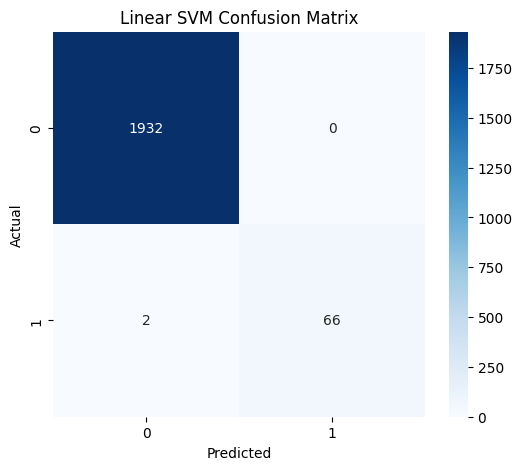

In [31]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Linear SVM Confusion Matrix")

plt.show()

In [32]:
rbf_svm = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf"))
])

rbf_svm.fit(X_train, y_train)

y_pred_rbf = rbf_svm.predict(X_test)

In [33]:
print("Accuracy:", accuracy_score(y_test, y_pred_rbf))
print("Precision:", precision_score(y_test, y_pred_rbf))
print("Recall:", recall_score(y_test, y_pred_rbf))
print("F1 Score:", f1_score(y_test, y_pred_rbf))

Accuracy: 0.999
Precision: 1.0
Recall: 0.9705882352941176
F1 Score: 0.9850746268656716


In [34]:
print(classification_report(y_test, y_pred_rbf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1932
           1       1.00      0.97      0.99        68

    accuracy                           1.00      2000
   macro avg       1.00      0.99      0.99      2000
weighted avg       1.00      1.00      1.00      2000



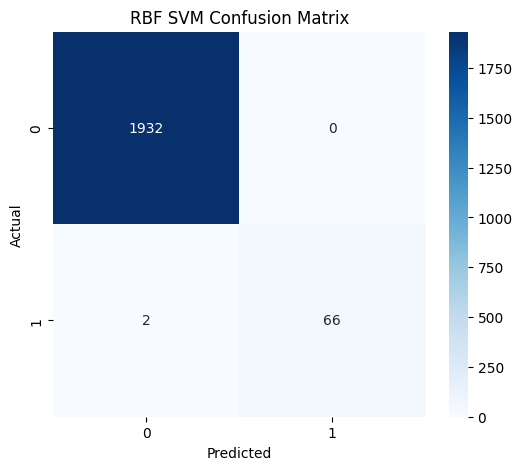

In [35]:
cm = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RBF SVM Confusion Matrix")

plt.show()

In [36]:
comparison_df = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM"],
    "Accuracy": [
        accuracy_score(y_test, linear_svm.predict(X_test)),
        accuracy_score(y_test, y_pred_rbf)
    ],
    "Precision": [
        precision_score(y_test, linear_svm.predict(X_test)),
        precision_score(y_test, y_pred_rbf)
    ],
    "Recall": [
        recall_score(y_test, linear_svm.predict(X_test)),
        recall_score(y_test, y_pred_rbf)
    ],
    "F1 Score": [
        f1_score(y_test, linear_svm.predict(X_test)),
        f1_score(y_test, y_pred_rbf)
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.999,1.0,0.970588,0.985075
1,RBF SVM,0.999,1.0,0.970588,0.985075


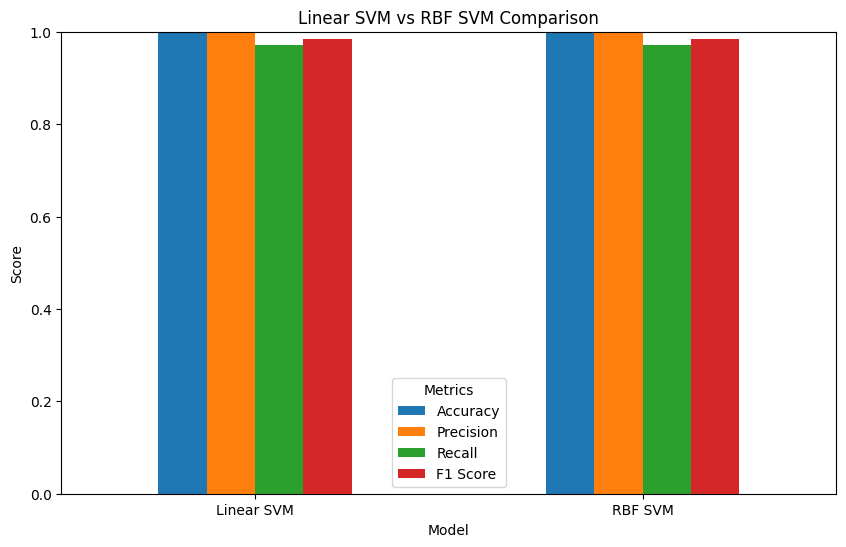

In [37]:
comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Linear SVM vs RBF SVM Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.show()

In [38]:
param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", "auto", 0.01, 0.1, 1]
}

grid_rbf = GridSearchCV(
    rbf_svm,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_rbf.fit(X_train, y_train)

print("Best Parameters:", grid_rbf.best_params_)
print("Best Score:", grid_rbf.best_score_)

Best Parameters: {'classifier__C': 0.1, 'classifier__gamma': 'scale'}
Best Score: 0.999125


In [39]:
best_rbf = grid_rbf.best_estimator_

y_pred_rbf_tuned = best_rbf.predict(X_test)

In [40]:
print("Accuracy:", accuracy_score(y_test, y_pred_rbf_tuned))
print("Precision:", precision_score(y_test, y_pred_rbf_tuned))
print("Recall:", recall_score(y_test, y_pred_rbf_tuned))
print("F1 Score:", f1_score(y_test, y_pred_rbf_tuned))

Accuracy: 0.999
Precision: 1.0
Recall: 0.9705882352941176
F1 Score: 0.9850746268656716


In [41]:
final_comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Tuned RBF SVM"],
    "Accuracy": [
        accuracy_score(y_test, linear_svm.predict(X_test)),
        accuracy_score(y_test, y_pred_rbf),
        accuracy_score(y_test, y_pred_rbf_tuned)
    ],
    "Precision": [
        precision_score(y_test, linear_svm.predict(X_test)),
        precision_score(y_test, y_pred_rbf),
        precision_score(y_test, y_pred_rbf_tuned)
    ],
    "Recall": [
        recall_score(y_test, linear_svm.predict(X_test)),
        recall_score(y_test, y_pred_rbf),
        recall_score(y_test, y_pred_rbf_tuned)
    ],
    "F1 Score": [
        f1_score(y_test, linear_svm.predict(X_test)),
        f1_score(y_test, y_pred_rbf),
        f1_score(y_test, y_pred_rbf_tuned)
    ]
})

final_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.999,1.0,0.9706,0.9851
1,RBF SVM,0.999,1.0,0.9706,0.9851
2,Tuned RBF SVM,0.999,1.0,0.9706,0.9851


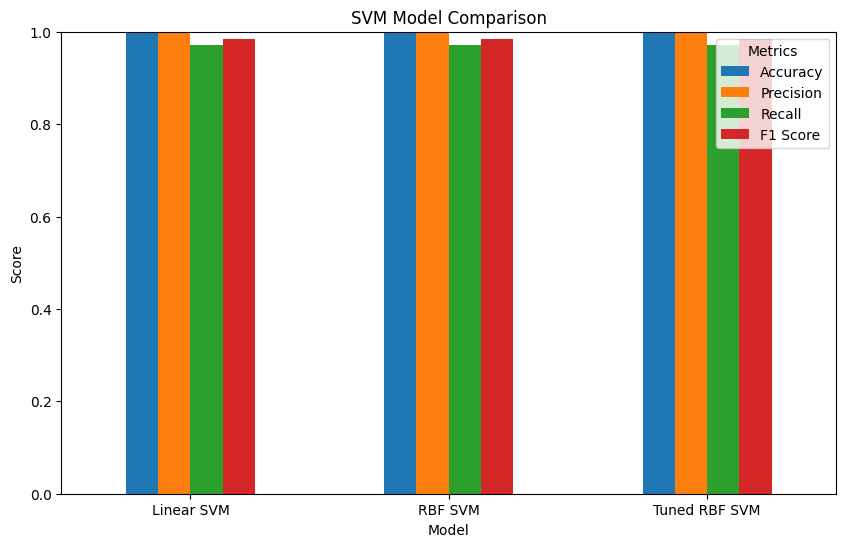

In [42]:
final_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("SVM Model Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.show()